# RAMS Analysis of a Passenger Train Fleet – 3. Failure Prediction
### Analyse RAMS d'une flotte de rames voyageurs – 3. Prédiction des pannes

> **Données synthétiques**, générées pour l'exercice. Elles ne proviennent d'aucun exploitant réel.

**Question (Q2) :** le temps écoulé depuis la dernière visite préventive augmente-t-il le risque de panne ? Autrement dit, faut-il anticiper les visites ?

**Ce que prédit le modèle :** pour une rame et un système donnés, à une date donnée, **y aura-t-il une panne dans les 30 jours ?** (classification binaire).

**Lien avec le notebook 2 :** l'analyse de Weibull n'a montré aucune usure entre deux pannes (β ≈ 1), mais elle ignorait les visites préventives. Le modèle teste directement l'effet du temps écoulé depuis la dernière visite.
**Résultats clés :**
- Trois modèles comparés : leurs performances sont proches (AUC ROC ≈ 0,70). La **régression logistique** est retenue pour sa simplicité.
- Le risque dépend surtout du **système**, de la **saison** et de l'**historique de la rame**.
- Le **retard de préventive n'a pas d'effet mesurable** : il ne concerne que 1,6 % des situations.
- En pratique, **cibler les portes double le taux de pannes détectées** ; le modèle n'apporte un gain qu'au-delà.

**Plan :** 1. Construction du jeu de données · 2. Valeurs manquantes · 3. Découpage et référence · 4. Régression logistique · 5. Effet du retard de préventive · 6. Forêt aléatoire · 7. Comparaison des modèles · 8. Lecture métier (lift) · 9. Conclusion

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.inspection import permutation_importance
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/oularealamako/01-nettoyage-railway/__notebook__.ipynb
/kaggle/input/notebooks/oularealamako/01-nettoyage-railway/__output__.json
/kaggle/input/notebooks/oularealamako/01-nettoyage-railway/__results__.html
/kaggle/input/notebooks/oularealamako/01-nettoyage-railway/custom.css
/kaggle/input/notebooks/oularealamako/01-nettoyage-railway/maintenance_rames_clean.csv
/kaggle/input/notebooks/oularealamako/01-nettoyage-railway/__results___files/__results___12_0.png
/kaggle/input/notebooks/oularealamako/01-nettoyage-railway/__results___files/__results___13_0.png
/kaggle/input/notebooks/oularealamako/01-nettoyage-railway/__results___files/__results___15_1.png
/kaggle/input/notebooks/oularealamako/01-nettoyage-railway/__results___files/__results___26_0.png
/kaggle/input/notebooks/oularealamako/01-nettoyage-railway/__results___files/__results___6_0.png
/kaggle/input/notebooks/oularealamako/01-nettoyage-railway/__results___files/__results___7_0.png


In [ ]:
df = pd.read_csv("../data/maintenance_rames_clean.csv",
                 sep=";", decimal=",", parse_dates=["Date intervention"])

cor = df[df["Type intervention"] == "corrective"]
prev = df[df["Type intervention"] == "préventive"]

print(df.shape)

(4053, 14)


## 1. Building the modelling dataset – Construction du jeu de données

**Principe : des « photos » mensuelles.** Le 1er de chaque mois, pour chaque couple rame/système, je calcule ce qu'on sait **à cette date** (les variables) et je regarde **ce qui se passe ensuite** (la cible).

**Règle d'or : aucune information du futur dans les variables.** Sinon le modèle « triche » : il paraît excellent en test mais est inutile en réalité (**fuite de données**).

| Variable | Sens métier |
|---|---|
| `jours_depuis_prev` | Temps écoulé depuis la dernière visite préventive |
| `ratio_retard` | Ce temps divisé par l'intervalle habituel des visites : au-dessus de 1, la visite est en retard |
| `jours_depuis_panne` | Temps écoulé depuis la dernière panne du même système |
| `pannes_12m` | Nombre de pannes du système sur cette rame dans les 12 derniers mois |
| `pannes_rame_12m` | Nombre de pannes de la rame, tous systèmes confondus, dans les 12 derniers mois |
| `mois` | Saisonnalité |
| `Système` | Niveau de risque propre à chaque système |
| **`panne_30j`** (cible) | 1 si une panne survient dans les 30 jours suivant la photo, 0 sinon |

In [3]:
# Intervalle habituel entre deux visites préventives, par système.
# Le plan de maintenance est connu à l'avance : ce n'est pas une fuite de données.
intervalle_prev = (prev.sort_values("Date intervention")
                   .groupby(["Matériel", "Système"])["Date intervention"]
                   .diff().dt.days
                   .groupby(prev["Système"]).median())

dates_photo = pd.date_range("2023-07-01", "2025-12-01", freq="MS")   # 1er de chaque mois
horizon = pd.Timedelta(days=30)

lignes = []
for (rame, systeme), g in df.groupby(["Matériel", "Système"]):
    d_prev = g.loc[g["Type intervention"] == "préventive", "Date intervention"]
    d_cor = g.loc[g["Type intervention"] == "corrective", "Date intervention"]
    d_cor_rame = cor.loc[cor["Matériel"] == rame, "Date intervention"]

    for d in dates_photo:
        passe_prev = d_prev[d_prev < d]          # variables : uniquement le passé
        passe_cor = d_cor[d_cor < d]
        lignes.append({
            "Matériel": rame,
            "Système": systeme,
            "date_photo": d,
            "jours_depuis_prev": (d - passe_prev.max()).days if len(passe_prev) else np.nan,
            "jours_depuis_panne": (d - passe_cor.max()).days if len(passe_cor) else np.nan,
            "pannes_12m": ((d_cor >= d - pd.Timedelta(days=365)) & (d_cor < d)).sum(),
            "pannes_rame_12m": ((d_cor_rame >= d - pd.Timedelta(days=365)) & (d_cor_rame < d)).sum(),
            "mois": d.month,
            "panne_30j": int(((d_cor >= d) & (d_cor < d + horizon)).any()),   # cible : le futur
        })

data = pd.DataFrame(lignes)
data["ratio_retard"] = data["jours_depuis_prev"] / data["Système"].map(intervalle_prev)

print(data.shape)
data.head()

(7200, 10)


,Matériel,Système,date_photo,jours_depuis_prev,jours_depuis_panne,pannes_12m,pannes_rame_12m,mois,panne_30j,ratio_retard
0,R001,bogies,2023-07-01,137.0,NaN,0,6,7,0,0.765363
1,R001,bogies,2023-08-01,168.0,NaN,0,7,8,0,0.938547
2,R001,bogies,2023-09-01,17.0,NaN,0,7,9,0,0.094972
3,R001,bogies,2023-10-01,47.0,NaN,0,10,10,0,0.262570
4,R001,bogies,2023-11-01,78.0,NaN,0,11,11,0,0.435754


In [4]:
print("Proportion de photos suivies d'une panne :", round(data["panne_30j"].mean(), 3))
print(data.groupby("Système")["panne_30j"].mean().round(3).sort_values())

Proportion de photos suivies d'une panne : 0.134
Système
bogies                     0.032
signalisation embarquée    0.054
traction                   0.082
pantographe                0.109
freinage                   0.140
climatisation              0.191
toilettes                  0.194
portes                     0.270
Name: panne_30j, dtype: float64


**Contrôles :**
- **Taille** : 30 rames × 8 systèmes × 30 mois = **7 200 photos** ✅
- **Déséquilibre des classes** : seulement **13,4 %** des photos sont suivies d'une panne. Un modèle qui répondrait toujours « pas de panne » aurait raison dans 86,6 % des cas sans en détecter aucune. L'exactitude (accuracy) est donc trompeuse ; j'utilise des métriques adaptées :
  - **AUC ROC** : capacité à classer les situations à risque avant les autres (0,5 = hasard, 1 = parfait) ;
  - **AUC PR** (précision-rappel) : plus adaptée aux classes déséquilibrées ; sa valeur « hasard » est le taux de pannes (≈ 0,13) ;
  - **lift** : gain obtenu en ciblant les situations jugées les plus à risque.
- **Cohérence avec le notebook 2** : si les pannes sont aléatoires (β ≈ 1), la probabilité d'au moins une panne en 30 jours vaut ≈ 1 − exp(−30 / MTBF).
  - Portes (MTBF ≈ 98 j) : ≈ 26 % attendus, **27 %** observés ✅
  - Bogies (MTBF ≈ 821 j) : ≈ 3,6 % attendus, **3,2 %** observés ✅

## 2. Missing values – Valeurs manquantes

In [5]:
data.isnull().sum()[lambda s: s > 0]

jours_depuis_prev        8
jours_depuis_panne    1322
ratio_retard             8
dtype: int64

- **`jours_depuis_prev` et `ratio_retard` (8 NaN)** : photos de juillet 2023 pour des couples dont la première visite préventive observée est postérieure (systèmes à visite semestrielle, comme les bogies ou la traction). Avec 8 lignes sur 7 200, je les **supprime**.
- **`jours_depuis_panne` (1 322 NaN)** : ce ne sont **pas des données manquantes**. Ils signifient « aucune panne depuis le début de l'observation », une information plutôt favorable à la rame.
  - Les remplacer par 0 voudrait dire « panne hier », l'inverse de la réalité ; par la médiane, ce serait inventer une panne.
  - Même logique que la censure dans Weibull : il s'est écoulé **au moins** le temps depuis le début de l'observation. Je remplace par cette durée et j'ajoute un indicateur `aucune_panne_passee` qui signale une valeur minimale, pas exacte.

In [6]:
debut = df["Date intervention"].min()

data["aucune_panne_passee"] = data["jours_depuis_panne"].isna().astype(int)
data["jours_depuis_panne"] = data["jours_depuis_panne"].fillna((data["date_photo"] - debut).dt.days)
data = data.dropna(subset=["jours_depuis_prev"])

print(data.shape)
print("NaN restants :", data.isnull().sum().sum())

(7192, 11)
NaN restants : 0


## 3. Time-based split and baseline – Découpage temporel et modèle de référence

**Pourquoi découper par date et pas au hasard ?**
- Deux photos consécutives d'une même rame se ressemblent beaucoup : réparties entre apprentissage et test, elles rendraient le score trop optimiste.
- En réalité, le modèle servira à prédire l'avenir à partir du passé : le test doit reproduire cette situation.

J'apprends donc sur **2023-2024** et je teste sur **2025**. La cible de la dernière photo d'apprentissage (1er décembre 2024) s'arrête au 31 décembre : aucun chevauchement avec le test.

**Pourquoi un modèle de référence ?** Pour savoir si le vrai modèle apporte quelque chose. La référence la plus simple prédit, pour chaque photo, le taux de panne moyen de son système.

In [7]:
train = data[data["date_photo"] < "2025-01-01"]
test = data[data["date_photo"] >= "2025-01-01"]
print("Apprentissage :", len(train), "| Test :", len(test))
print("Taux de pannes : apprentissage", round(train["panne_30j"].mean(), 3), "| test", round(test["panne_30j"].mean(), 3))

taux_systeme = train.groupby("Système")["panne_30j"].mean()
proba_ref = test["Système"].map(taux_systeme)

print("AUC ROC référence :", round(roc_auc_score(test["panne_30j"], proba_ref), 3))
print("AUC PR référence  :", round(average_precision_score(test["panne_30j"], proba_ref), 3))

Apprentissage : 4312 | Test : 2880
Taux de pannes : apprentissage 0.135 | test 0.134
AUC ROC référence : 0.692
AUC PR référence  : 0.235


Même cette référence ne joue pas « à la tombola » : **AUC ROC 0,692** (contre 0,5 pour le hasard) et **AUC PR 0,235** (contre 0,134), soit environ 1,75 fois mieux que le hasard, rien qu'en connaissant le système.

Il ne faut pas attendre un score proche de 1 : Weibull a montré une forte part aléatoire dans les pannes. L'objectif réaliste est de **battre la référence**.

## 4. Logistic regression – Régression logistique

Deux choix guidés par l'exploration :
- `ratio_retard` plutôt que `jours_depuis_prev` : 60 jours est un retard pour les portes, pas pour les bogies ; le ratio est comparable entre systèmes.
- La saisonnalité n'est pas la même partout : je crée deux variables dédiées, `clim_ete` (juin-août) et `frein_hiver` (novembre-février).

In [8]:
def preparer(d):
    X = d[["ratio_retard", "jours_depuis_panne", "aucune_panne_passee",
           "pannes_12m", "pannes_rame_12m"]].copy()
    X["clim_ete"] = ((d["Système"] == "climatisation") & d["mois"].isin([6, 7, 8])).astype(int)
    X["frein_hiver"] = ((d["Système"] == "freinage") & d["mois"].isin([11, 12, 1, 2])).astype(int)
    X = X.join(pd.get_dummies(d["Système"], prefix="sys", drop_first=True, dtype=int))
    return X

X_train, y_train = preparer(train), train["panne_30j"]
X_test, y_test = preparer(test), test["panne_30j"]

# StandardScaler : variables à la même échelle, pour des coefficients comparables
modele_log = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
modele_log.fit(X_train, y_train)

proba_log = modele_log.predict_proba(X_test)[:, 1]
print("AUC ROC logistique :", round(roc_auc_score(y_test, proba_log), 3))
print("AUC PR logistique  :", round(average_precision_score(y_test, proba_log), 3))

AUC ROC logistique : 0.697
AUC PR logistique  : 0.258


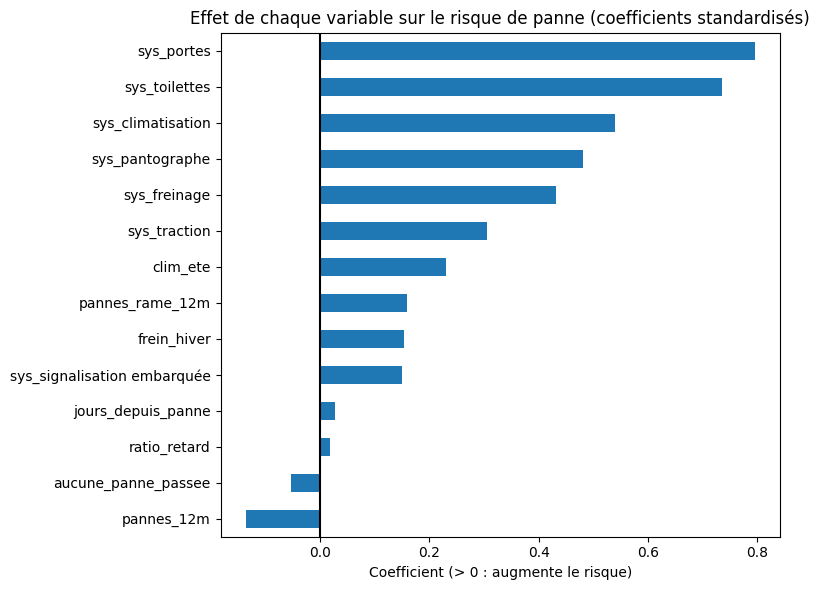

In [9]:
coefs = pd.Series(modele_log[-1].coef_[0], index=X_train.columns).sort_values()

coefs.plot(kind="barh", figsize=(8, 6))
plt.axvline(0, color="black")
plt.title("Effet de chaque variable sur le risque de panne (coefficients standardisés)")
plt.xlabel("Coefficient (> 0 : augmente le risque)")
plt.tight_layout()
plt.show()

**Scores :** gain modeste mais réel. L'AUC ROC passe de 0,692 à 0,697 et l'AUC PR de 0,235 à 0,258 (≈ +10 % sur la métrique la plus adaptée). L'essentiel reste porté par le système.

**Coefficients :**
- **Les systèmes dominent** (portes, toilettes, climatisation en tête), en cohérence avec le MTBF.
- **`clim_ete` et `frein_hiver` sont positifs** : le modèle retrouve les saisonnalités de l'exploration.
- **`pannes_rame_12m` est positif** : une rame qui a eu beaucoup de pannes récemment reste à risque (effet R010/R018).
- **`jours_depuis_panne` est quasi nul** : le temps écoulé depuis la dernière panne ne change pas le risque, ce qui rejoint Weibull (β ≈ 1, pannes « sans mémoire »).
- **`ratio_retard` est quasi nul** : le retard de préventive pèse très peu (voir section 5).
- **`pannes_12m` est négatif**, ce qui surprend. Je ne l'interprète pas seul : cette variable recoupe `pannes_rame_12m`, `jours_depuis_panne` et `aucune_panne_passee`. Quand des variables se recoupent (**multicolinéarité**), la régression répartit leur effet de façon instable, et un coefficient isolé peut changer de signe.

## 5. Effect of preventive delay – Pourquoi le retard pèse-t-il si peu ?

Deux hypothèses :
1. **Il n'y a presque pas de retards dans les données** : on ne peut pas mesurer l'effet d'une situation qui n'arrive presque jamais.
2. **L'effet n'est pas linéaire** : le risque pourrait ne monter qu'au-delà d'un seuil, ce qu'une régression logistique (linéaire) ne capte pas.

In [10]:
print(data["ratio_retard"].describe().round(3))
print("Part des photos en retard :", round((data["ratio_retard"] > 1).mean() * 100, 1), "%")

tranches = pd.cut(data["ratio_retard"], bins=[0, 0.25, 0.5, 0.75, 1, 1.25, 3])
data.groupby(tranches, observed=True)["panne_30j"].agg(taux_panne="mean", nb_photos="count").round(3)

count    7192.000
mean        0.508
std         0.300
min         0.006
25%         0.258
50%         0.506
75%         0.759
max         2.023
Name: ratio_retard, dtype: float64
Part des photos en retard : 1.6 %


,taux_panne,nb_photos
ratio_retard,,
"(0.0, 0.25]",0.129,1762
"(0.25, 0.5]",0.126,1816
"(0.5, 0.75]",0.142,1763
"(0.75, 1.0]",0.136,1733
"(1.0, 1.25]",0.207,87
"(1.25, 3.0]",0.129,31


In [11]:
# Incertitude sur le taux de panne juste après l'échéance (tranche 1,0 – 1,25)
p, n = 0.207, 87
marge = 1.96 * np.sqrt(p * (1 - p) / n)
print(f"Intervalle de confiance à 95 % : {p - marge:.3f} à {p + marge:.3f}")

Intervalle de confiance à 95 % : 0.122 à 0.292


**Hypothèse 1 confirmée :** `ratio_retard` est réparti presque uniformément entre 0 et 1. Seules **1,6 %** des photos (118 sur 7 192) sont en retard : le plan préventif est très bien respecté.

**Hypothèse 2 : un signal possible, non démontré.**
- **Avant l'échéance, le risque est plat** (12,6 % à 14,2 %) : il n'augmente pas à l'approche de la visite. Troisième méthode cohérente avec β ≈ 1.
- **Juste après l'échéance**, le taux monte à **20,7 %**, mais sur 87 photos seulement : l'intervalle à 95 % (12 % à 29 %) contient le taux habituel. **On ne peut pas exclure le hasard.**
- Au-delà de 1,25, 31 photos seulement : trop peu pour conclure.

**Conclusion :** le plan préventif est respecté dans 98,4 % des cas, ce qui limite la possibilité de mesurer l'effet d'un retard. C'est une **absence de preuve, pas une preuve d'absence**.

**Piste métier :** puisque le risque n'augmente pas à l'approche de l'échéance, l'intervalle entre deux visites n'est peut-être pas optimal. Les données ne permettent pas d'extrapoler au-delà, mais elles justifieraient un **essai pilote** d'allongement sur quelques rames, avec un suivi rapproché.

## 6. Random forest – Forêt aléatoire

Une forêt aléatoire combine des centaines d'arbres de décision et peut capter des effets de seuil et des combinaisons que la logistique rate. Si elle ne fait pas mieux, c'est qu'il y a peu de signal non linéaire caché.

`min_samples_leaf=20` limite le **surapprentissage** (chaque feuille doit contenir au moins 20 photos). Pas besoin de standardiser : un arbre compare des valeurs à des seuils.

In [12]:
foret = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1)
foret.fit(X_train, y_train)
proba_foret = foret.predict_proba(X_test)[:, 1]

auc_train = roc_auc_score(y_train, foret.predict_proba(X_train)[:, 1])
auc_test = roc_auc_score(y_test, proba_foret)
print(f"AUC apprentissage : {auc_train:.3f} | AUC test : {auc_test:.3f}")

AUC apprentissage : 0.804 | AUC test : 0.693


In [13]:
# Forêt plus contrainte : réduit-elle le surapprentissage ?
foret_100 = RandomForestClassifier(n_estimators=300, min_samples_leaf=100, random_state=42, n_jobs=-1)
foret_100.fit(X_train, y_train)
print(f"min_samples_leaf=100 → AUC apprentissage : {roc_auc_score(y_train, foret_100.predict_proba(X_train)[:, 1]):.3f}"
      f" | AUC test : {roc_auc_score(y_test, foret_100.predict_proba(X_test)[:, 1]):.3f}")

min_samples_leaf=100 → AUC apprentissage : 0.694 | AUC test : 0.681


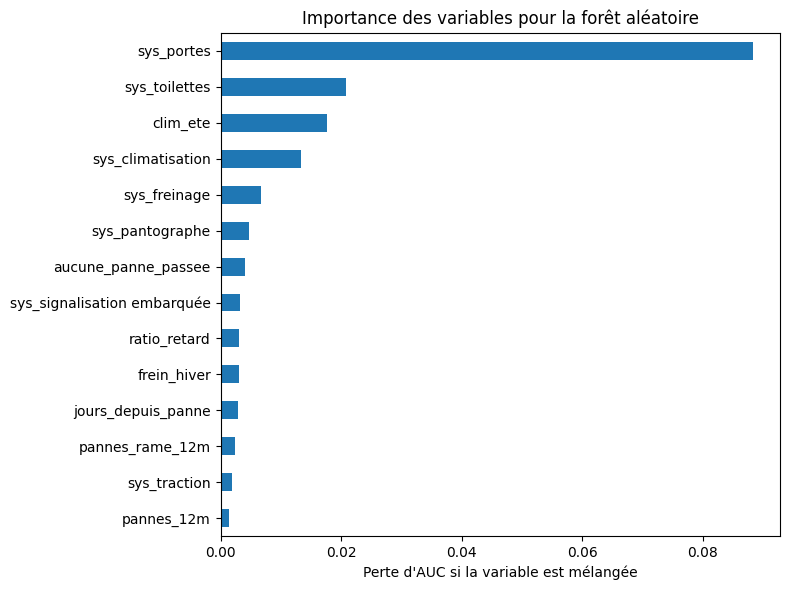

In [14]:
# Importance par permutation : perte d'AUC quand on mélange une variable dans le jeu de test
imp = permutation_importance(foret, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=42)
importance = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()

importance.plot(kind="barh", figsize=(8, 6))
plt.title("Importance des variables pour la forêt aléatoire")
plt.xlabel("Perte d'AUC si la variable est mélangée")
plt.tight_layout()
plt.show()

**Surapprentissage modéré :** 0,804 en apprentissage contre 0,693 en test. La forêt apprend des particularités de 2023-2024 qui ne se répètent pas en 2025. En la contraignant davantage (`min_samples_leaf=100`), le surapprentissage disparaît (0,694 contre 0,681), mais le score de test baisse légèrement : la limite vient des **données**, pas du modèle.

**Importance des variables :** les mêmes variables dominent que pour la logistique, le système (portes très loin devant) puis `clim_ete`. `ratio_retard` reste presque inutile (perte d'AUC ≈ 0,003) : même un modèle capable de capter un seuil n'en tire rien. Les variables d'historique pèsent très peu, ce qui est cohérent avec des pannes « sans mémoire ».

## 7. Model comparison – Comparaison des modèles

In [15]:
resultats = pd.DataFrame({
    "AUC ROC": [roc_auc_score(y_test, p) for p in (proba_ref, proba_log, proba_foret)],
    "AUC PR": [average_precision_score(y_test, p) for p in (proba_ref, proba_log, proba_foret)],
}, index=["Référence (système)", "Régression logistique", "Forêt aléatoire"]).round(3)
resultats

,AUC ROC,AUC PR
Référence (système),0.692,0.235
Régression logistique,0.697,0.258
Forêt aléatoire,0.693,0.251


- **AUC ROC** : les trois modèles sont au coude à coude (0,692 / 0,697 / 0,693), sans différence pratique.
- **AUC PR** : la logistique fait le mieux (0,258) et la forêt ne la dépasse pas (0,251).

À performances égales, je retiens le modèle le plus **simple et interprétable** : la **régression logistique**. Qu'un modèle plus complexe ne fasse pas mieux est en soi une information : il y a peu d'effet non linéaire caché dans les données.


## 8. Business reading – Que vaut le modèle pour prioriser les inspections ?

Une AUC de 0,70 ne parle pas à un responsable de flotte. La question utile : **si j'inspecte en priorité les situations jugées les plus à risque, est-ce que je trouve plus de pannes ?** Le **lift** est le rapport entre le taux de panne du groupe ciblé et le taux moyen : un lift de 2 signifie deux fois plus de pannes trouvées qu'en inspectant au hasard.

In [16]:
test_eval = test.assign(proba=proba_log, proba_ref=proba_ref)
taux_moyen = test_eval["panne_30j"].mean()

lignes_lift = []
for part in [0.10, 0.125, 0.20, 0.30]:
    n = int(len(test_eval) * part)
    top_log = test_eval.nlargest(n, "proba")
    top_ref = test_eval.nlargest(n, "proba_ref")
    lignes_lift.append({
        "part_inspectee_%": part * 100,
        "lift_logistique": top_log["panne_30j"].mean() / taux_moyen,
        "lift_reference": top_ref["panne_30j"].mean() / taux_moyen,
        "pannes_captees_logistique_%": top_log["panne_30j"].sum() / test_eval["panne_30j"].sum() * 100,
    })

pd.DataFrame(lignes_lift).round(2)

,part_inspectee_%,lift_logistique,lift_reference,pannes_captees_logistique_%
0,10.0,2.00,2.23,20.00
1,12.5,1.99,2.37,24.94
2,20.0,1.94,1.90,38.70
3,30.0,1.86,1.76,55.84


**Lecture :**
- **Jusqu'à ≈ 12,5 % des inspections**, ce qui correspond à peu près à toutes les photos de portes, la **référence est meilleure** (lift de 2,23 à 2,37 contre 2,00). Cibler les portes est déjà la meilleure stratégie.
- **À partir de 20 %**, la référence doit choisir parmi les autres systèmes sans information. La logistique, qui connaît la saison et l'historique de la rame, prend l'avantage (1,94 contre 1,90 à 20 %, 1,86 contre 1,76 à 30 %).
- Le modèle **priorise, il ne détecte pas tout** : en inspectant 10 % des situations, il capte 20 % des pannes.

**Conclusion :** l'essentiel du gain vient du système. Cibler les portes double le taux de pannes détectées (lift ≈ 2,3). Le modèle n'apporte un avantage que lorsqu'on élargit les inspections au-delà des portes. Savoir montrer qu'une règle simple fait presque aussi bien qu'un modèle est un résultat utile avant d'investir dans un outil prédictif.

## 9. Conclusion

- **Performances** : trois modèles comparés, AUC ROC ≈ 0,70 pour tous. La régression logistique est retenue (meilleure AUC PR, 0,258 contre 0,235 pour la référence, et la plus interprétable).
- **Facteurs de risque** : le système, la saison (climatisation en été, freinage en hiver) et l'historique récent de la rame.
- **Question 2 – retard de préventive** : aucun effet mesurable. Le plan est respecté dans 98,4 % des cas ; juste après l'échéance, le taux de panne passe de 13 % à 21 %, sans significativité statistique.
- **Cohérence** : trois méthodes (MTBF, Weibull, taux de panne selon l'avancement du cycle préventif) concluent à des pannes à forte part aléatoire, ce qui explique la performance limitée des modèles.
- **Usage métier** : pour prioriser les inspections, cibler les portes suffit à doubler le taux de pannes détectées ; le modèle apporte un complément modeste au-delà.

**Limites :**
- Données synthétiques.
- Très peu de situations de retard préventif : l'effet du retard ne peut être ni confirmé ni exclu.
- Horizon fixe de 30 jours et photos mensuelles.
- Multicolinéarité entre les variables d'historique : leurs coefficients individuels ne sont pas interprétables.
- Données manquantes pour aller plus loin : kilométrage, état des équipements (capteurs), situations de retard plus variées.

La synthèse globale du projet (nettoyage, exploration, modélisation) est dans le **README** du dépôt.